# The Weight-Space Lifecycle: Retrain, Gate, Promote, Roll Back

**Calderwood Insurance**, the claims desk, January 2027. Tom Okafor, a Grade 1
handler, has agreed £2,800 with a customer and asks the desk's small model
whether he can pay it himself.

In September the answer was no: a Grade 1 handler's payout authority was
£2,500. On 1 January it rose to £3,000. The model was trained in September, so
it says no, confidently, in the same words it was trained on. Nothing about it
looks broken. Its weights are simply out of date.

January brought four changes. The Grade 1 limit rose to £3,000, the deadline
for getting an Amber Pack to the Counter Fraud Unit went from 2 to 3 working
days, payments over £25,000 now need clearing by the Settlement Review Team
before Tally releases them, and the upload portal Drop was replaced by
Compass. A memory unit can be corrected in a second. Weights have to be
retrained, and a retrained model has to earn its place before it replaces the
one that is serving.

This notebook runs that loop on notebook 03's small model: detect that the
weights are stale, retrain with the new facts and a replay of the old ones,
decide with a paired significance test and regression tests whether the new
version is better, and then move the serving pointer or leave it, with the way
back rehearsed either way.

It is the last of four notebooks in `beyond_the_context_window/`. It needs no
API key. It uses notebook 03's adapter if it is there, and trains one with
the same recipe if it isn't.

## Key takeaways

- ***Stale weights don't look broken.*** *`v1` passed none of 13 January questions, and three of its answers stated September's values in the words of its training rows.*
- ***Two triggers: one from the facts, one from the model.*** *The data trigger fired from the policy table alone (4 changes, 22 training rows stating an old value); the performance trigger fired on a frozen test set.*
- ***Training on the changes alone is catastrophic forgetting.*** *`v2-no-replay` learned 12 of the 13 changes and kept 3 of the 52 September facts that were still true.*
- ***Replay keeps the old facts, and costs some of the new ones.*** *With replay, `v2` kept 24 of 52 and learned 8 of 13; a fresh adapter on the corrected set kept 30 and learned 7.*
- ***A gate written in advance can say no to everything, and here it did.*** *All three candidates beat `v1` on the new facts at p < 0.05, and each failed a regression test, so `v1` stayed in service.*
- ***When the gate says no, the interim fix is in token space.*** *Four memory units can be corrected today; the next candidate can take its time, and be judged on a set no attempt has seen.*

## How this notebook is organised

| Part | What happens | What you have at the end |
|---|---|---|
| **1 · The use case** | January 2027, and the lifecycle as a loop | The problem, the loop and its vocabulary |
| **2 · Setup and the model in service** | The small model, its helpers, and version `v1` | The September model, serving |
| **3 · What changed, as data** | Round 2's values from `calderwood_world.py`; stale rows rewritten, new rows and a frozen test set generated by rule | Training rows and a test set for January |
| **4 · The retrain trigger** | A data trigger and a performance trigger, run against `v1` | The evidence that `v1` is stale |
| **5 · Retraining, with and without replay** | Two candidates from `v1`: new rows only, and new rows with the old ones replayed | Two adapters to judge |
| **6 · The promotion gate** | Every version on the frozen sets; a paired exact McNemar test; regression tests; one more attempt if every candidate fails | A verdict per candidate |
| **7 · Promotion and rollback** | `ACTIVE` moves only for a candidate that passed; the rollback drill runs either way | A tested way back, and a history |
| **8 · Wrap-up** | What the numbers do and don't show | What to distrust, and round 3 |

### ⭐ The live path

About fifteen minutes. Training and evaluation take a few minutes each on an
Apple Silicon laptop; on a slow machine, run the notebook beforehand and show
the saved outputs.

| Stop | Section | What to show | Minutes |
|---|---|---|---|
| 1 | 1.1 ⭐ Tom's £2,800 | Stale weights, in one question | 2 |
| 2 | 1.2 ⭐ The lifecycle as a loop | Trigger, retrain, gate, promote, roll back | 2 |
| 3 | 4.2 ⭐ The performance trigger | `v1` answers January's questions with September's values | 2 |
| 4 | 6.2 ⭐ The paired test | McNemar on the frozen set, worked through | 2 |
| 5 | 6.3 ⭐ The verdicts | What the gate says about each candidate, and which test decides | 2 |
| 6 | 6.4 ⭐ The next attempt | What a rejection teaches, and a candidate trained differently | 2 |
| 7 | 7.1 ⭐ Promote or keep, then rehearse the way back | Tom's question as the pointer moves and moves back | 3 |

# Part 1 · The use case

This part is the *why*: what goes wrong when knowledge in weights changes,
and the loop that keeps it right. No code runs here.

## 1.1 ⭐ Tom's £2,800

Section 7.1 asks it of the model in service. The question is new in January,
and the answer is September's:

> **Tom:** *"I'm Grade 1 and the settlement is £2,800. Can I pay it myself?"*
>
> **The September model (`v1`):** *"No. A Grade 1 handler's TPA is £2,500, so £800 needs referring up."*

The limit is September's, in the words of a training row. (The £800 is the
small model's own slip; notebook 03 measured how often it makes them.)

In token space this is a one-record fix: update the memory unit, and the next
retrieval carries the new limit. In weight space the old value is spread
across an adapter's parameters, and the only way to change it is to train
again. That raises four questions, and each Part of this notebook answers one:

| Question | Part |
|---|---|
| **How do you know the weights are stale?** A model doesn't announce it | 4 · The retrain trigger |
| **What do you train on?** Only the new facts, or the new facts and the old ones | 5 · Retraining |
| **How do you know the new version is better,** and better at the new facts without being worse at the old ones? | 6 · The promotion gate |
| **What if you're wrong?** | 7 · Promotion and rollback |

## 1.2 ⭐ The lifecycle as a loop

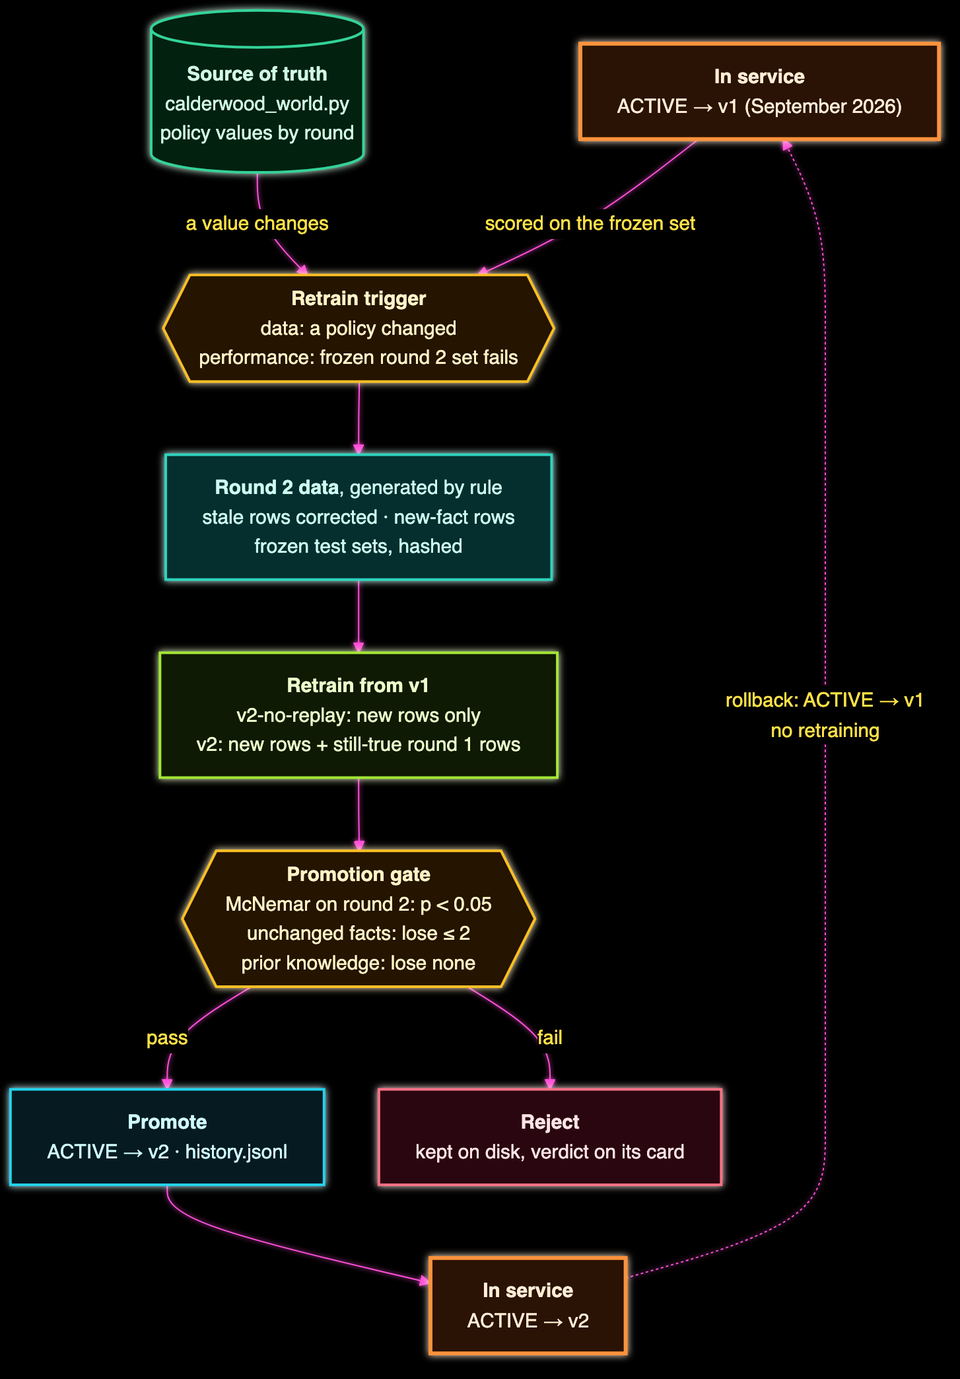

**How to read it.** Start at the top: the source of truth on the left, the
model in service on the right. Either can fire the trigger: a value changes in
Calderwood's policy table, or the model in service fails a frozen test set. Retraining produces a
*candidate*, never a replacement. The gate compares the candidate with the
version in service on frozen test sets, and only a pass moves the `ACTIVE`
pointer. Every version stays on disk, so rollback is moving the pointer back.

The terms, each defined once:

- **A retrain trigger is a rule that says the weights need retraining.** A *data trigger* fires when the facts change; a *performance trigger* fires when a measured score falls.
- **Replay is mixing earlier training rows that are still true into the new training run**, so training on new facts doesn't overwrite old ones. Overwriting them is **catastrophic forgetting**.
- **A candidate is a newly trained version that hasn't been promoted.**
- **A frozen test set is a set of questions fixed before training and never changed afterwards.** Every version is scored on the same questions, so the comparison is paired.
- **McNemar's test asks whether two models' disagreements on the same questions lean one way.** Questions both get right or both get wrong say nothing about which is better; only the disagreements count.
- **A regression test checks that something that worked before still works.** Here: the September facts that didn't change, and general knowledge.
- **Promotion is moving `ACTIVE` to a candidate; rollback is moving it back.**

> ### 📌 Key Takeaways
> - Stale weights don't look broken: they answer confidently with last quarter's values.
> - The loop is trigger, retrain, gate, promote, and keep the way back open.
> - A retrained model is a candidate until a gate written in advance says otherwise.

# Part 2 · Setup and the model in service

This part loads the small model and the helpers it needs (the same chat
template, generation and training loop as notebook 03), then puts version
`v1` in service.

## 2.1 · Setup

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `PYTORCH_MPS_HIGH_WATERMARK_RATIO` | Environment setting | Caps how much of a Mac's shared memory PyTorch may take | Two trainings and several hundred generations run in this notebook |
| `cw` (`calderwood_world`) | Calderwood world | Calderwood's facts, with a value per round | Round 2's values are read from it, never typed |
| `SLMS` | Notebook setting | `models/slm/`, the small model's registry from notebook 03 | Versions, cards, `ACTIVE` and the history log live here |

In [ ]:
import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

# Cap what PyTorch may take from a Mac's shared memory (set before torch is imported).
os.environ.setdefault("PYTORCH_MPS_HIGH_WATERMARK_RATIO", "0.5")
os.environ.setdefault("PYTORCH_MPS_LOW_WATERMARK_RATIO", "0.4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TQDM_DISABLE"] = "1"                      # no progress bars in the saved outputs
warnings.filterwarnings("ignore", message=".*IProgress.*")

**Then the libraries**, with their progress bars and routine warnings turned
down so the outputs below show results, and the device chosen.

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from huggingface_hub.utils import logging as hub_logging
from transformers.utils import logging as hf_logging

import calderwood_world as cw  # the shared Calderwood world, beside this notebook

hf_logging.disable_progress_bar(); hf_logging.set_verbosity_error(); hub_logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=DeprecationWarning)
DEVICE = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
SEED = 7
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", DEVICE, "| torch", torch.__version__)

In [ ]:
DATA = Path("..") / "data" / "calderwood"
DATASETS = Path("datasets")
SLMS = Path("models") / "slm"
SMALL = "Qwen/Qwen3-0.6B"


def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def write_jsonl(path, rows):
    Path(path).write_text("".join(json.dumps(r, ensure_ascii=False) + "\n" for r in rows))
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:16]


held_out = read_jsonl(DATA / "eval.jsonl")
sft = read_jsonl(DATASETS / "sft.jsonl")
SYSTEM = held_out[0]["messages"][0]["content"]
print(f"{len(held_out)} held-out questions, {len(sft)} round 1 SFT rows")

## 2.2 · The helpers from notebook 03

The same scoring rule, chat template, generation and training loop as
notebook 03, repeated here so this notebook runs on its own. They are
described there; the names are listed so you can find them below.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `score(answer, must_include)` | Notebook helper | Every group of key terms has an alternative in the answer | The one judge, as in notebook 03 |
| `prompt_ids(messages)` | Notebook helper | Qwen3's chat template with thinking off, as token ids | Shared by training and inference |
| `ask(model, question)` | Notebook helper | Greedy answer to one question, under the system prompt | Every evaluation in this notebook |
| `encode_row(row)`, `batch_tensors(rows)` | Notebook helpers | SFT rows as ids and labels; a left-padded batch | Training input |
| `train_lora(model, rows, epochs, lr)` | Notebook helper | The LoRA training loop with answer-only logits. One change from notebook 03: each batch of 8 runs as two micro-batches of 4, with the loss summed over the batch's answer tokens, so the gradient is the same and a step's peak memory is about 1 GB lower | Used for each candidate; three trainings run in this notebook, and a batch of the eight longest rows can otherwise reach the cap set in 2.1 |

In [ ]:
def normalise(text):
    return re.sub(r"(?<=\d),(?=\d)", "", text.lower().replace("\u2019", "'"))


def _pattern(alt):
    p = re.escape(alt)
    p = r"(?<!\d)" + p if alt[0].isdigit() else p
    return p + r"(?!\d)" if alt[-1].isdigit() else p


def score(answer, must_include):
    a = normalise(answer)
    return all(any(re.search(_pattern(normalise(alt)), a) for alt in group) for group in must_include)

In [ ]:
from transformers import AutoModelForCausalLM, AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(SMALL)
DTYPE = torch.bfloat16 if DEVICE in ("mps", "cuda") else torch.float32


def load_base():
    model = AutoModelForCausalLM.from_pretrained(SMALL, dtype=DTYPE).to(DEVICE)
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
    return model


def prompt_ids(messages):
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, enable_thinking=False,
                                         tokenize=True, return_dict=False)


@torch.no_grad()
def ask(model, question, max_new_tokens=96):
    ids = torch.tensor([prompt_ids([{"role": "system", "content": SYSTEM}, {"role": "user", "content": question}])], device=DEVICE)
    out = model.generate(input_ids=ids, attention_mask=torch.ones_like(ids), max_new_tokens=max_new_tokens,
                         do_sample=False, pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, ids.shape[1]:], skip_special_tokens=True).strip()

In [ ]:
def encode_row(row):
    prompt = prompt_ids(row["messages"][:2])
    answer = tokenizer(row["messages"][2]["content"] + "<|im_end|>\n", add_special_tokens=False).input_ids
    return prompt + answer, [-100] * len(prompt) + answer


def batch_tensors(rows):
    width = max(len(ids) for ids, _ in rows)
    pad = lambda seq, value: [value] * (width - len(seq)) + seq
    ids = torch.tensor([pad(i, tokenizer.pad_token_id) for i, _ in rows], device=DEVICE)
    mask = torch.tensor([pad([1] * len(i), 0) for i, _ in rows], device=DEVICE)
    labels = torch.tensor([pad(l, -100) for _, l in rows], device=DEVICE)
    keep = max(sum(t != -100 for t in l) for _, l in rows) + 1
    return ids, mask, labels, keep

In [ ]:
def train_lora(model, rows, epochs, lr, batch_size=8, warmup=0.06, seed=SEED, micro_batch=4):
    params = [p for p in model.parameters() if p.requires_grad]
    optimiser = torch.optim.AdamW(params, lr=lr, weight_decay=0.0)
    steps = epochs * math.ceil(len(rows) / batch_size); warm = max(1, int(warmup * steps))
    schedule = torch.optim.lr_scheduler.LambdaLR(optimiser, lambda s: (s + 1) / warm if s < warm else (steps - s) / (steps - warm))
    rng, history = random.Random(seed), []
    model.train()
    for epoch in range(epochs):
        order, total = rng.sample(range(len(rows)), len(rows)), 0.0
        for start in range(0, len(order), batch_size):
            batch = [rows[i] for i in order[start:start + batch_size]]
            answer_tokens = sum(sum(t != -100 for t in labels) for _, labels in batch)
            for part in range(0, len(batch), micro_batch):   # half a batch at a time, one gradient per batch
                ids, mask, labels, keep = batch_tensors(batch[part:part + micro_batch])
                logits = model(input_ids=ids, attention_mask=mask, logits_to_keep=keep).logits[:, :-1].float()
                loss = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), labels[:, -keep + 1:].reshape(-1),
                                       ignore_index=-100, reduction="sum") / answer_tokens
                loss.backward(); total += loss.item()
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            optimiser.step(); schedule.step(); optimiser.zero_grad()
        history.append(round(total / math.ceil(len(rows) / batch_size), 4))
    model.eval()
    return history

## 2.3 · Version `v1`, in service

Notebook 03 saved its adapter as `models/slm/v1` and pointed `ACTIVE` at it.
If it isn't there (this notebook was run on its own), the next cell trains
`v1` with notebook 03's recipe (rank 16 on every projection, 5 epochs, batch 8,
learning rate 2e-4) and registers it the same way. Either way, `v1` is in
service when the cell finishes, and the history log records how it got there.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `register(version, card)` | Notebook helper | Writes a version's card | Every version, promoted or not, has one |
| `activate(version, reason, pointer=)` | Notebook helper | Moves a pointer (`ACTIVE` by default) and appends to `history.jsonl` | The only way the serving version changes |
| `PeftModel.from_pretrained(base, path, adapter_name=)` | PEFT API | Loads an adapter onto a base model under a name | One base model can hold several adapters and switch between them |

In [ ]:
from peft import LoraConfig, PeftModel, get_peft_model

LORA = {"r": 16, "lora_alpha": 32, "lora_dropout": 0.05,
        "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]}


def register(version, card):
    (SLMS / version).mkdir(parents=True, exist_ok=True)
    card = {"version": version, "base_model": SMALL, "created": datetime.now(timezone.utc).isoformat(timespec="seconds"), **card}
    (SLMS / version / "card.json").write_text(json.dumps(card, indent=2) + "\n")


def activate(version, reason, pointer="ACTIVE"):
    previous = json.loads((SLMS / pointer).read_text())["version"] if (SLMS / pointer).exists() else None
    (SLMS / pointer).write_text(json.dumps({"version": version}) + "\n")
    with open(SLMS / "history.jsonl", "a") as log:
        log.write(json.dumps({"at": datetime.now(timezone.utc).isoformat(timespec="seconds"), "pointer": pointer,
                              "from": previous, "to": version, "reason": reason}) + "\n")

In [ ]:
for old in [p for p in SLMS.glob("*") if p.is_dir() and p.name != "v1"] + [SLMS / "history.jsonl", SLMS / "ACTIVE", SLMS / "STAGING"]:
    shutil.rmtree(old) if old.is_dir() else old.unlink(missing_ok=True)   # start from v1 on every run
if not (SLMS / "v1" / "adapter").exists():
    print("notebook 03's adapter isn't here: training v1 with the same recipe")
    model = get_peft_model(load_base(), LoraConfig(task_type="CAUSAL_LM", **LORA))
    history = train_lora(model, [encode_row(r) for r in sft], epochs=5, lr=2e-4)
    model.save_pretrained(str(SLMS / "v1" / "adapter"))
    register("v1", {"trained_on": "datasets/sft.jsonl", "loss_by_epoch": history, "world_round": cw.ROUND_NAMES[1]})
    del model; gc.collect()
activate("v1", f"in service since {cw.ROUND_NAMES[1]}")
model = PeftModel.from_pretrained(load_base(), str(SLMS / "v1" / "adapter"), adapter_name="v1")
model.eval()
print("ACTIVE:", json.loads((SLMS / "ACTIVE").read_text())["version"], "| adapters loaded:", list(model.peft_config))

> ### 📌 Key Takeaways
> - The helpers are notebook 03's, repeated so this notebook runs on its own.
> - `v1` is an adapter on disk, a card and a line in the history log.
> - One base model can carry several adapters; switching between them is how this notebook serves and rolls back.

# Part 3 · What changed, as data

This part reads January's changes from `calderwood_world.py`, turns them into
training rows and a frozen test set by rule, and writes both to `datasets/`,
labelled as generated.

## 3.1 · January 2027, read from the world

`cw.POLICIES` holds every Calderwood policy with a value per round, and
`cw.policy(name, key, round)` returns the value in force in a round. So
January's changes don't have to be typed: compare every policy's value in
round 1 with its value in round 2, and keep the ones that differ.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `cw.POLICIES`, `cw.policy(name, key, round=)` | Calderwood world | Policy values by round; the value in force in a round | The single source of truth for every number in this Part |
| `changes(before, after)` | Notebook helper | Every policy whose value differs between two rounds | The data trigger in Part 4 is this list being non-empty |

In [ ]:
def changes(before=1, after=2):
    out = []
    for name, values in cw.POLICIES.items():
        keys = list(values) if all(isinstance(k, str) for k in values) else [None]
        for key in keys:
            old, new = cw.policy(name, key, round=before), cw.policy(name, key, round=after)
            if old != new:
                out.append({"policy": name if key is None else f"{name}.{key}", "round 1": old, "round 2": new})
    return pd.DataFrame(out)


CHANGES = changes(1, 2)
print(f"{cw.ROUND_NAMES[1]} -> {cw.ROUND_NAMES[2]}:")
print(CHANGES.to_string(index=False))

**How to read the result.** Four policies differ between September and
January, the four from the introduction: the Grade 1 limit (2500 → 3000), the
Amber Pack deadline (2 → 3 working days), the Settlement Review Team threshold
(`None` in round 1, because the rule didn't exist, and 25000 in round 2), and
the upload portal (Drop → Compass). None of them is typed in this notebook.
`changes(2, 3)` returns April's two changes the same way, which is where round
3 would start.

## 3.2 · Round 2 training rows, generated by rule

Two kinds of row, both **generated by rule from `calderwood_world.py`** and
labelled `source: generated (round 2)`:

1. **Corrected rows.** Every round 1 row that states a changed value gets the
   new value substituted: `£2,500` becomes `£3,000`, `2 working days` becomes
   `3 working days`, and `Drop` becomes `Compass`. The question stays the
   same; the answer changes. These rows *replace* the stale ones: a training
   set holding both *"£2,500"* and *"£3,000"* for the same question teaches
   the model to be unsure, not to update.
2. **New-fact rows.** The Settlement Review Team clearance didn't exist in
   round 1, so nothing can be corrected into it. Its rows are written from
   templates, with the team, the threshold and the error code read from the
   world (`cw.TEAMS`, `cw.policy("srt_threshold", round=2)`, `cw.ERRORS`).

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `SUBSTITUTIONS` | Data | Pairs of (round 1 text, round 2 text), each built from `cw` values | The whole correction, in three lines |
| `stale(row)` | Notebook helper | Whether a row states a round 1 value that changed | Picks the rows to correct, and later the rows not to replay |
| `round2_rows` | Dataset | Corrected rows plus new-fact rows | What every candidate trains on |

In [ ]:
g1_old, g1_new = cw.policy("tpa", "grade_1", round=1), cw.policy("tpa", "grade_1", round=2)
amber_old, amber_new = cw.policy("amber_pack_days", round=1), cw.policy("amber_pack_days", round=2)
portal_old, portal_new = cw.policy("upload_portal", round=1), cw.policy("upload_portal", round=2)
SUBSTITUTIONS = [(re.escape(cw.pounds(g1_old)), cw.pounds(g1_new)),
                 (rf"\b{amber_old} working days", f"{amber_new} working days"),
                 (rf"\b{portal_old}\b", portal_new)]


def stale(row):
    return any(re.search(old, m["content"]) for old, _ in SUBSTITUTIONS for m in row["messages"][1:])


def correct(row):
    messages = [dict(m) for m in row["messages"]]
    for old, new in SUBSTITUTIONS:
        for m in messages[1:]:
            m["content"] = re.sub(old, new, m["content"])
    return {**row, "id": row["id"].replace("sft_", "r2_"), "messages": messages, "source": "generated (round 2)"}


corrected = [correct(r) for r in sft if stale(r)]
print(len(corrected), "round 1 rows state a changed value, by fact:", pd.Series([r["kb_ref"] or "multi_hop" for r in corrected]).value_counts().to_dict())
print("before:", next(r for r in sft if stale(r) and r["kb_ref"] == "tpa_g1")["messages"][2]["content"])
print("after :", next(r for r in corrected if r["kb_ref"] == "tpa_g1")["messages"][2]["content"])

In [ ]:
srt = cw.policy("srt_threshold", round=2)
SRT_NAME, SRT_ALIAS = "Settlement Review Team", cw.TEAMS["Settlement Review Team"]["aliases"][0]
fact = f"Payments over {cw.pounds(srt)} need clearing by the {SRT_NAME} ({SRT_ALIAS}) before Tally releases them."
NEW_FACTS = [
    ("What does the SRT do?", f"The {SRT_NAME} (SRT) {cw.TEAMS[SRT_NAME]['does']}."),
    ("What is the Settlement Review Team?", f"The {SRT_NAME} (SRT) {cw.TEAMS[SRT_NAME]['does']}."),
    ("Which payments need SRT clearance?", fact),
    (f"Does a payment over {cw.pounds(srt)} need anything extra before it's released?", fact),
    ("What does TLY-512 mean?", f"TLY-512 means {cw.ERRORS['TLY-512']}. {fact}"),
    ("Tally is holding a payment with TLY-512. What do I do?", f"It's waiting for {SRT_NAME} (SRT) clearance. {fact}"),
    (f"Is {portal_old} still in use?", f"No. {portal_old} was retired in {cw.ROUND_NAMES[2]}; customers now upload through {portal_new}."),
    ("What replaced Drop?", f"{portal_new} replaced {portal_old} as the secure upload portal in {cw.ROUND_NAMES[2]}."),
]
new_rows = [{"id": f"r2_new_{i:02d}", "messages": [{"role": "system", "content": SYSTEM}, {"role": "user", "content": q},
             {"role": "assistant", "content": a}], "kb_ref": "srt" if "SRT" in a or "Settlement" in a else "compass",
             "category": "policy", "source": "generated (round 2)"} for i, (q, a) in enumerate(NEW_FACTS, 1)]
round2_rows = corrected + new_rows
print(len(round2_rows), "round 2 training rows:", len(corrected), "corrected +", len(new_rows), "new")
print("example:", new_rows[2]["messages"][1]["content"], "->", new_rows[2]["messages"][2]["content"])

## 3.3 · The frozen test sets

Three sets, fixed now, before any training, and written to disk with a hash so
that every version is scored on exactly the same questions:

| Set | Questions | What it checks | Where it comes from |
|---|---|---|---|
| **Round 2** | The January facts | That a candidate learned the change | The four held-out questions about changed facts, with round 2 key terms, plus scenario questions generated by rule from `cw` in wordings no training row uses |
| **Unchanged round 1** | Every held-out question whose fact didn't change | Regression: that the September facts that are still true survived | `eval.jsonl`, unchanged |
| **Prior knowledge** | The five general questions | Regression: forgetting of what the base model knew | `eval.jsonl`, unchanged |

The scenario questions use handlers from `cw.HANDLERS` and amounts chosen to
fall *between* the old and new values, where the old weights give the wrong
answer: a Grade 1 handler paying £2,800 is over September's limit and under
January's.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `CHANGED_FACTS` | Data | The held-out ids whose answers changed, with their round 2 key terms | These move from the round 1 set to the round 2 set |
| `frozen` | Dataset | Every frozen question with its `set`, key terms and `source` | Written to `datasets/round2_frozen.jsonl`; its hash goes on every card |

In [ ]:
g1 = [h for h, grade in cw.HANDLERS.items() if grade == "grade_1"]
money = lambda v: [cw.pounds(v).lower(), str(v)]
CHANGED_FACTS = {"eval_tpa_g1": [money(g1_new)], "eval_amber_2d": [[f"{amber_new} working days"]],
                 "eval_drop": [[portal_new.lower()]], "eval_bcn217": [["25mb", "25 mb"], [portal_new.lower()]]}
generated = [
    *[(f"{name} is Grade 1 and has agreed {cw.pounds(amount)} on a claim. Can {name.split()[0]} pay it without referring it up?",
       [money(g1_new)]) for name, amount in zip(g1, (2800, 2650, 2950))],
    ("What's the payout authority of a Grade 1 claims handler at the moment?", [money(g1_new)]),
    ("I spotted fraud indicators on a claim this morning. How long do I have to get it to the Counter Fraud Unit?", [[f"{amber_new} working days"]]),
    ("A customer needs to send us a large video of the damage. Which portal should they use?", [[portal_new.lower()]]),
    (f"Gwen has approved a {cw.pounds(31500)} settlement, within her authority. Who has to clear it before Tally pays it?", [["srt", "settlement review team"]]),
    (f"A {cw.pounds(42000)} payment is sitting in Tally and won't release. Which team is it waiting for?", [["srt", "settlement review team"]]),
    ("Above what amount does a claim payment need clearing before Tally releases it?", [money(srt)]),
]
by_id = {q["id"]: q for q in held_out}
frozen = ([{"id": qid, "set": "round 2", "question": by_id[qid]["question"], "must_include": keys, "source": "eval.jsonl, round 2 keys"}
           for qid, keys in CHANGED_FACTS.items()]
          + [{"id": f"r2_gen_{i}", "set": "round 2", "question": q, "must_include": keys, "source": "generated (round 2)"}
             for i, (q, keys) in enumerate(generated, 1)]
          + [{"id": q["id"], "set": "prior knowledge" if q["category"] == "prior_knowledge" else "unchanged round 1",
              "question": q["question"], "must_include": q["must_include"], "source": "eval.jsonl"}
             for q in held_out if q["id"] not in CHANGED_FACTS])
print(pd.Series([f["set"] for f in frozen]).value_counts().to_dict())

Before anything is written: no frozen question may appear in any training
row, round 1 or round 2. Then both files go to `datasets/`, and their hashes
are kept for the cards.

In [ ]:
training_questions = {normalise(r["messages"][1]["content"]) for r in sft + round2_rows}
leaks = [f["id"] for f in frozen if normalise(f["question"]) in training_questions]
assert not leaks, leaks
FROZEN_SHA = write_jsonl(DATASETS / "round2_frozen.jsonl", frozen)
ROUND2_SHA = write_jsonl(DATASETS / "round2_train.jsonl", round2_rows)
print(f"no frozen question in any training row; wrote round2_frozen.jsonl ({len(frozen)} questions, sha256 {FROZEN_SHA}) "
      f"and round2_train.jsonl ({len(round2_rows)} rows, sha256 {ROUND2_SHA})")

> ### 📌 Key Takeaways
> - The changes are computed from the world's policy table, not typed: the same code finds round 3's.
> - Stale rows are corrected and replace the originals; a new fact gets new rows from templates.
> - The frozen sets are fixed and hashed before any training, and checked against every training row.

# Part 4 · The retrain trigger

Two triggers, one about the facts and one about the model. Either is enough to
start a retrain; here both fire, and this Part shows the evidence for each.

## 4.1 · The data trigger

The data trigger needs no model at all: a fact in the source of truth changed,
and the training set states the old value. It fires as soon as the policy
table changes, before any handler gets a wrong answer.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `data_trigger` | Data | Whether any policy changed and how many training rows state a changed value | The cheap, early trigger |

In [ ]:
stale_rows = [r for r in sft if stale(r)]
data_trigger = {"policies changed": len(CHANGES), "v1 training rows stating an old value": len(stale_rows),
                "share of v1's training set": f"{len(stale_rows) / len(sft):.0%}",
                "fires": len(CHANGES) > 0 and len(stale_rows) > 0}
print(data_trigger)

## 4.2 ⭐ The performance trigger

The performance trigger runs the model in service on the round 2 frozen set
and looks for two things: the pass rate, and **stale answers**, which state a
round 1 value that has changed. A stale answer is worse than a wrong one: it
is a confident, specific, out-of-date fact.

The rule: retrain if fewer than 80% of round 2 questions pass, or if any
answer is stale.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `evaluate(model, adapter, questions)` | Notebook helper | Switches to an adapter, answers every question, scores it, and marks stale answers | Used for the trigger now and the gate in Part 6 |
| `STALE`, `is_stale(answer)` | Notebook helper | Pairs of (round 1 value, round 2 value); an answer is stale if it states an old value without the new one | *"Compass replaced Drop"* is right; *"use Drop"* is stale |

In [ ]:
money_re = lambda v: rf"(?<!\d){re.escape(normalise(cw.pounds(v)))}(?!\d)"
STALE = [(money_re(g1_old), money_re(g1_new)),                                   # (round 1 value, round 2 value)
         (rf"(?<!\d){amber_old} working days", rf"(?<!\d){amber_new} working days"),
         (rf"\b{portal_old.lower()}\b", rf"\b{portal_new.lower()}\b")]


def is_stale(answer):
    """States a round 1 value that changed, without the round 2 value beside it."""
    a = normalise(answer)
    return any(re.search(old, a) and not re.search(new, a) for old, new in STALE)


def evaluate(model, adapter, questions):
    model.set_adapter(adapter)
    rows = []
    for q in questions:
        answer = ask(model, q["question"])
        rows.append({"version": adapter, "id": q["id"], "set": q["set"], "answer": answer,
                     "passed": score(answer, q["must_include"]), "stale": is_stale(answer)})
    return pd.DataFrame(rows)


round2 = [f for f in frozen if f["set"] == "round 2"]
t0 = time.perf_counter()
v1_round2 = evaluate(model, "v1", round2)
rate, n_stale = v1_round2.passed.mean(), int(v1_round2.stale.sum())
print(f"v1 on the round 2 set: {v1_round2.passed.sum()}/{len(round2)} passed, {n_stale} stale answers ({time.perf_counter() - t0:.0f} s)")
print("performance trigger fires:", rate < 0.8 or n_stale > 0)

In [ ]:
for _, r in v1_round2.iterrows():
    q = next(f["question"] for f in round2 if f["id"] == r["id"])
    flag = "STALE" if r["stale"] else ("pass" if r["passed"] else "fail")
    print(f"[{flag:<5}] {q[:72]}\n         {r['answer'][:150]}")

**How to read the result.**

- **0 of 13 passed and 3 answers are stale, so the trigger fires on both
  counts.** The 13 answers took 9 seconds.
- **The stale answers are September's training rows, stated as fact:**
  *"A Grade 1 handler's TPA is £2,500."*, *"Within 2 working days of seeing the
  indicators"*, *"Send the customer a Drop link"*. Each was right in September,
  and nothing in the answer hints that it might not be now.
- **The other ten are wrong in the house style.** The three Grade 1 scenarios
  get a limit of £1,500, which is Calderwood's Green Lane threshold, not a
  payout authority. The three Settlement Review Team questions get teams and
  codes assembled from ones the model does know (Payments Control Review,
  `TLY-409`). That rule didn't exist in September, so there is nothing for `v1`
  to be stale about: it invents.
- **A pass rate says the model is wrong; the stale count says why.** A model
  that is guessing needs more or better training; a model that remembers last
  quarter needs retraining on what changed.

> ### 📌 Key Takeaways
> - A data trigger fires when the source of truth changes, before anyone is given a wrong answer.
> - A performance trigger needs a frozen test set for the new facts, and a check for stale values.
> - Stale answers are the expensive failure: specific, confident and out of date.

# Part 5 · Retraining, with and without replay

Two candidates, both continuing from `v1`'s adapter, so each starts with
everything `v1` knows. They differ in one thing: what they are trained on.

| Candidate | Trained on | Rows | The bet |
|---|---|---|---|
| `v2-no-replay` | Round 2 rows only | the corrected and new rows | Training on what changed is enough, and the rest stays put |
| `v2` | Round 2 rows **plus every round 1 row that is still true** | the same, plus the replay | The old facts have to be rehearsed, or the new ones overwrite them |

Both get the same number of optimiser steps, so neither wins by training
longer, and the same learning rate, 1e-4: half of `v1`'s, because a
continuing run starts from a trained adapter and needs a smaller push.

## 5.1 · Retrain on the new rows only

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `continue_from(version)` | Notebook helper | Loads a version's adapter onto a fresh base model as a *trainable* copy | Each candidate starts from `v1`, and `v1`'s files are never modified |
| `train_candidate(name, rows)` | Notebook helper | Continues from `v1` for about `STEPS` steps on `rows`, saves the adapter as a new version and writes its card | Both candidates go through it |
| `STEPS` | Notebook setting | Optimiser steps per candidate | Equal for both, so the comparison is about data, not effort |
| `model.to("cpu")`, `model.to(DEVICE)` | PyTorch API | Moves the model in service off the GPU while a candidate trains, and back afterwards | Two copies of the base model and a training step don't fit together under the cap set in 2.1 |

In [ ]:
STEPS, LR, BATCH = 60, 1e-4, 8


def continue_from(version):
    return PeftModel.from_pretrained(load_base(), str(SLMS / version / "adapter"), is_trainable=True)


def train_candidate(name, rows):
    model.to("cpu")   # the model in service steps off the GPU while a candidate trains
    candidate = continue_from("v1")
    epochs = max(1, round(STEPS * BATCH / len(rows)))
    t0 = time.perf_counter()
    history = train_lora(candidate, [encode_row(r) for r in rows], epochs=epochs, lr=LR, batch_size=BATCH)
    candidate.save_pretrained(str(SLMS / name / "adapter"))
    register(name, {"continued_from": "v1", "rows": len(rows), "epochs": epochs, "learning_rate": LR, "loss_by_epoch": history,
                    "trained_on": {"round2_train.jsonl": ROUND2_SHA}, "frozen_sets": FROZEN_SHA, "world_round": cw.ROUND_NAMES[2]})
    print(f"{name}: {len(rows)} rows x {epochs} epochs in {time.perf_counter() - t0:.0f} s; loss {history[0]} -> {history[-1]}")
    del candidate; gc.collect(); torch.mps.empty_cache() if DEVICE == "mps" else None
    model.to(DEVICE)

In [ ]:
train_candidate("v2-no-replay", round2_rows)

## 5.2 · Retrain with replay

Replay puts the round 1 rows that are still true back into the run. "Still
true" is the same test as before: a row that states a changed value is not
replayed, because its corrected version is already among the round 2 rows.
That is the whole difference between the two candidates.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `replay` | Data | Round 1 rows with no stale value | The rehearsal |

In [ ]:
replay = [r for r in sft if not stale(r)]
print(f"replay: {len(replay)} of {len(sft)} round 1 rows are still true")
train_candidate("v2", round2_rows + replay)

**How to read the result.**

- **228 of the 250 round 1 rows are still true** and go back in; the other 22
  are replaced by their corrections.
- **Equal steps, different data.** `v2-no-replay` saw its 30 rows 16 times and
  `v2` saw its 258 rows twice: 64 and 66 optimiser steps, about two and a half
  to three minutes each.
- **The two losses can't be compared, and the gap between them is a warning.**
  `v2-no-replay` ends at 0.0004: it has memorised 30 rows. `v2` starts at 0.19,
  because it already knew 228 of its rows, and ends at 0.07. A training loss
  near zero says a model fits its training rows; it says nothing about what
  else it still knows. Part 6 measures that.

> ### 📌 Key Takeaways
> - Continue from the version in service, so the candidate starts with what it knew.
> - Replay only what is still true; a stale row and its correction in one run teach doubt.
> - Hold the number of optimiser steps fixed when comparing training sets.

# Part 6 · The promotion gate

This part scores `v1` and both candidates on all three frozen sets, then
applies a gate written down before the numbers:

| Test | Rule | Why |
|---|---|---|
| **Learned the change** | On the round 2 set, the candidate beats `v1` in a paired exact McNemar test at p < 0.05 | Better on the new facts, by more than the luck of a few questions |
| **Kept the old facts** | On the unchanged round 1 set, the candidate passes no more than 2 fewer questions than `v1` | Regression, with a stated tolerance of 2 of 52 (about 4%) |
| **Kept general knowledge** | On the prior-knowledge set, the candidate passes at least as many as `v1` | Regression, with no tolerance: five questions leave no room |

## 6.1 · Every version on every frozen set

One base model, three adapters loaded under their names, and `set_adapter()`
to switch. All three answer all the frozen questions with greedy decoding, so
the comparison is paired: same questions, same decoding, only the weights
differ.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `model.load_adapter(path, adapter_name=)` | PEFT API | Adds a saved adapter to the model under a name | The candidates join `v1` on one base model |
| `scores` | Data | One row per version per frozen question | Everything the gate reads |

In [ ]:
for name in ("v2-no-replay", "v2"):
    model.load_adapter(str(SLMS / name / "adapter"), adapter_name=name)
t0 = time.perf_counter()
others = [f for f in frozen if f["set"] != "round 2"]
scores = pd.concat([v1_round2, evaluate(model, "v1", others)]
                   + [evaluate(model, name, frozen) for name in ("v2-no-replay", "v2")], ignore_index=True)
print(f"{len(scores)} answers in {time.perf_counter() - t0:.0f} s")
table = scores.pivot_table(index="set", columns="version", values="passed", aggfunc="sum")[["v1", "v2-no-replay", "v2"]]
table["questions"] = scores[scores.version == "v1"].groupby("set").size()
print(table.to_string())
print("stale answers:", scores.groupby("version").stale.sum().to_dict())

**How to read the result.**

- **`v1` passes 0 of 13 round 2 questions, 27 of 52 unchanged ones and 3 of 5
  general ones.** Those are the numbers each candidate has to beat on the first
  set and hold on the other two.
- **`v2-no-replay` learned January and forgot September.** It passes 12 of 13
  on round 2, the best of any version, and 3 of 52 on the facts that didn't
  change, and it drops two general questions. Thirty rows seen sixteen times
  pulled the whole adapter towards them. That is catastrophic forgetting, in
  one column of a table.
- **`v2`, with replay, kept most of September (24 of 52) and learned less of
  January (8 of 13).** Its two stale answers show some September values
  surviving beside the new ones.
- **Stale answers: 8 for `v1` across all three sets, 2 for `v2`, none for
  `v2-no-replay`.** Three of `v1`'s eight are the round 2 answers in 4.2.

## 6.2 ⭐ The paired test

Two versions answered the same questions. For each question there are four
outcomes: both right, both wrong, only `v1` right (call the count `b`), only
the candidate right (`c`). The first two say nothing about which is better. If
the two versions were equally good, each disagreement would be equally likely
to go either way, like a fair coin, so `c` would follow a binomial
distribution with `n = b + c` and `p = 0.5`.

The **exact McNemar test** asks how surprising the observed split is under
that fair coin. Its p-value is the two-sided binomial probability of a split at
least as lopsided as the one observed. With small numbers this matters: 6
disagreements all going the candidate's way give p = 0.031, while 5 of 6 give
p = 0.22, not enough to conclude anything.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `scipy.stats.binomtest(k, n, p=0.5)` | SciPy API | The exact binomial test | McNemar's exact test is this, applied to the disagreements |
| `mcnemar(before, after, subset)` | Notebook helper | `b`, `c` and the two-sided exact p-value for two versions on one set | The gate's first test |

In [ ]:
from scipy.stats import binomtest


def mcnemar(before, after, subset):
    s = scores[scores.set == subset].pivot_table(index="id", columns="version", values="passed").astype(bool)
    b = int((s[before] & ~s[after]).sum())   # only the version in service right
    c = int((~s[before] & s[after]).sum())   # only the candidate right
    p = binomtest(c, b + c, 0.5).pvalue if b + c else 1.0
    return {"b (only before right)": b, "c (only after right)": c, "p": round(float(p), 4)}


for candidate in ("v2-no-replay", "v2"):
    print(candidate, "vs v1 on the round 2 set:", mcnemar("v1", candidate, "round 2"))

**How to read the result.** Both candidates have `b = 0`: there is no
round 2 question that `v1` got right and a candidate got wrong, because `v1` got
none right. So every disagreement goes the candidate's way, and the test turns
on how many there are: 12 of 12 gives p = 0.0005, and 8 of 8 gives p = 0.0078.
Both are below 0.05, so both candidates learned the change by more than the
luck of a few questions. This is the first of three tests.

## 6.3 ⭐ The verdicts

The three tests, for each candidate, and a verdict. Nothing here is tuned to
the result: the thresholds are the ones in the table at the top of this Part.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `GATE` | Notebook setting | `alpha` 0.05, unchanged-set tolerance 2, prior-knowledge tolerance 0 | The rule, as data |
| `gate(candidate)` | Notebook helper | Applies the three tests against `v1` and returns a table and a verdict | The promotion decision |

In [ ]:
GATE = {"alpha": 0.05, "unchanged_tolerance": 2, "prior_tolerance": 0}


def gate(candidate):
    passed = scores.pivot_table(index="set", columns="version", values="passed", aggfunc="sum")
    test = mcnemar("v1", candidate, "round 2")
    checks = [
        ("learned the change", f"c={test['c (only after right)']}, b={test['b (only before right)']}, p={test['p']}",
         test["c (only after right)"] > test["b (only before right)"] and test["p"] < GATE["alpha"]),
        ("kept the old facts", f"{passed.loc['unchanged round 1', candidate]} vs {passed.loc['unchanged round 1', 'v1']}",
         passed.loc["unchanged round 1", candidate] >= passed.loc["unchanged round 1", "v1"] - GATE["unchanged_tolerance"]),
        ("kept general knowledge", f"{passed.loc['prior knowledge', candidate]} vs {passed.loc['prior knowledge', 'v1']}",
         passed.loc["prior knowledge", candidate] >= passed.loc["prior knowledge", "v1"] - GATE["prior_tolerance"])]
    return pd.DataFrame(checks, columns=["test", f"{candidate} vs v1", "pass"]), all(ok for *_, ok in checks)


verdicts = {}
for candidate in ("v2-no-replay", "v2"):
    table, verdicts[candidate] = gate(candidate)
    print(table.to_string(index=False), "\n  verdict:", "PROMOTE" if verdicts[candidate] else "REJECT", "\n")

**How to read the result.** Both are rejected, by different tests.

- **`v2-no-replay` fails two of the three.** It learned the change
  (p = 0.0005), then kept 3 of 52 old facts against a floor of 25, and 1 of 5
  general answers against 3.
- **`v2` fails one, by one question.** It learned the change (p = 0.0078) and
  kept general knowledge (3 against 3), but kept 24 of the 52 old facts, and
  the rule allows `v1`'s 27 less 2, which is 25.
- **One question short is still short.** The tolerance was written before the
  numbers. Moving it to 3 now would pass `v2` and make the rule mean whatever
  the latest candidate needs. The verdict stands, `v1` stays in service, and
  6.4 makes one more attempt.

## 6.4 ⭐ The next attempt

A rejected candidate is evidence, and the card says what it shows. Continuing
from `v1` gave each candidate about 65 optimiser steps on top of weights
that already held September's values: the new rows had to push those values
out, and the old rows had to hold on, in the same few steps.

So when neither candidate passes, the next attempt changes the starting point,
and with it the recipe: **a fresh adapter, trained from the base model on the
corrected training set** (the 228 round 1 rows that are still true and the 30
round 2 rows) with exactly the recipe that made `v1`: rank 16, five epochs,
batch 8, learning rate 2e-4. It costs a full training run instead of a short
one, and it gives January's rows the same five passes September's rows got.

The gate is not changed. Loosening a rule after a candidate fails it turns the
rule into a formality. One caution comes with a second attempt: it is judged on
the same frozen sets that rejected the first two, and every attempt scored on a
set uses up a little of its independence (try enough candidates and one passes
by luck). A production team keeps one more frozen set, untouched by any
attempt, for the last check before a version serves.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `train_fresh(name, rows)` | Notebook helper | Trains a new adapter from the base model with `v1`'s recipe, saves it and writes its card | The other way to retrain: from the start, on data that is now right |
| `v3` | Version | The fresh adapter, trained only if every earlier candidate was rejected | Judged by the same `gate()` against `v1` |

In [ ]:
def train_fresh(name, rows, epochs=5, lr=2e-4):
    model.to("cpu")   # as in train_candidate
    candidate = get_peft_model(load_base(), LoraConfig(task_type="CAUSAL_LM", **LORA))
    t0 = time.perf_counter()
    history = train_lora(candidate, [encode_row(r) for r in rows], epochs=epochs, lr=lr, batch_size=BATCH)
    candidate.save_pretrained(str(SLMS / name / "adapter"))
    register(name, {"continued_from": "base", "rows": len(rows), "epochs": epochs, "learning_rate": lr, "loss_by_epoch": history,
                    "trained_on": {"round2_train.jsonl": ROUND2_SHA, "replay": "datasets/sft.jsonl rows with no stale value"},
                    "frozen_sets": FROZEN_SHA, "world_round": cw.ROUND_NAMES[2]})
    print(f"{name}: {len(rows)} rows x {epochs} epochs from the base model in {time.perf_counter() - t0:.0f} s; "
          f"loss {history[0]} -> {history[-1]}")
    del candidate; gc.collect(); torch.mps.empty_cache() if DEVICE == "mps" else None
    model.to(DEVICE)


if any(verdicts.values()):
    print("a candidate passed the gate: no further attempt")
else:
    train_fresh("v3", round2_rows + replay)

In [ ]:
if "v3" not in verdicts and (SLMS / "v3" / "adapter").exists():
    model.load_adapter(str(SLMS / "v3" / "adapter"), adapter_name="v3")
    scores = pd.concat([scores, evaluate(model, "v3", frozen)], ignore_index=True)
    table, verdicts["v3"] = gate("v3")
    print(table.to_string(index=False), "\n  verdict:", "PROMOTE" if verdicts["v3"] else "REJECT", "\n")
    print("stale answers:", scores.groupby("version").stale.sum().to_dict())
    print("v3 against v1 on the unchanged round 1 set:", mcnemar("v1", "v3", "unchanged round 1"))

**How to read the result.**

- **`v3` trained from the base model in about six minutes (five epochs over
  258 rows) and learned the change**: 7 of 13 round 2 questions against `v1`'s
  0, p = 0.0156, and no stale answers at all.
- **It kept the old facts better than `v1` itself: 30 of 52 against 27.**
  Question by question it wins 7 and loses 4 against `v1` on that set
  (p = 0.55). A fresh adapter isn't `v1` plus January; it is a different model
  that knows a slightly different part of September.
- **It failed on general knowledge, 2 of 5 against `v1`'s 3**, and the rule
  for that set allows no drop. One question decided it.
- **Three candidates, three rejections, each for a different reason:**
  forgetting, a little forgetting, and one general question. The gate did what
  it was written to do, and two things follow. The desk keeps a model that is
  stale on four facts, so the interim fix belongs in token space: correct the
  four memory units, and send questions about them to the large model with
  memory (notebook 03's set-up (b)) until a candidate passes. And the next
  attempt should be judged on a frozen set that no attempt has seen, with a
  general-knowledge set large enough to carry a stated tolerance, both decided
  before that attempt is trained.

> ### 📌 Key Takeaways
> - Score every version on the same frozen questions; then only the disagreements carry information.
> - McNemar's exact test is a binomial test on the disagreements; with a handful of them, only a lopsided split is evidence.
> - The gate has three tests and all three must pass: learn the change, keep the old facts, keep general knowledge.

# Part 7 · Promotion and rollback

The gate has spoken; this Part acts on it. The verdict is written onto each
candidate's card, a passing candidate becomes `ACTIVE`, and a rollback drill
shows the way back.

## 7.1 ⭐ Promote or keep, then rehearse the way back

The serving path reads `ACTIVE` and switches the model to that adapter. A
rejected candidate stays on disk with its card, because the record of what
was tried and why it failed is worth keeping. Then the drill, which has two
forms:

- **If a candidate passed**, it is promoted and the drill runs on `ACTIVE`:
  Tom asks his question under the new version; suppose a problem is reported
  after the switch, and roll back; he asks again; then, the drill over, roll
  forward.
- **If none passed**, `ACTIVE` doesn't move: a rejected candidate never serves
  the desk. The way back is still worth rehearsing before it is needed, so the
  drill runs on a second pointer, `STAGING`, that nothing on the desk reads.
  It moves to the best rejected candidate, Tom asks, and it moves back.

| Name | Kind | What it does | Why it matters here |
|---|---|---|---|
| `serve(question, pointer=)` | Notebook helper | Reads a pointer (`ACTIVE` by default), switches to that adapter, answers | The whole serving path for the small model |
| `TOM` | Data | Tom's question from 1.1, built from `cw`: his name, his grade and an amount between the two limits | The question that shows which version is serving |

In [ ]:
def serve(question, pointer="ACTIVE"):
    version = json.loads((SLMS / pointer).read_text())["version"]
    model.set_adapter(version)
    return version, ask(model, question)


for candidate, ok in verdicts.items():
    card = json.loads((SLMS / candidate / "card.json").read_text())
    card["gate"] = {"verdict": "promote" if ok else "reject", "against": "v1", "rule": GATE}
    (SLMS / candidate / "card.json").write_text(json.dumps(card, indent=2) + "\n")
TOM = f"I'm {cw.GRADE_NAMES[cw.grade_of('Tom Okafor')]} and the agreed settlement is {cw.pounds(2800)}. Can I pay it myself?"
winner = next((c for c in ("v2", "v3", "v2-no-replay") if verdicts.get(c)), None)
if winner:
    activate(winner, "promotion gate passed")
else:
    print("no candidate passed the gate: ACTIVE stays at v1")
print(TOM)
print("  ", *serve(TOM))

In [ ]:
if winner:
    activate("v1", "rollback drill: a problem is reported after the switch")
    print("  ", *serve(TOM))
    activate(winner, "rollback drill over")
    print("  ", *serve(TOM))
else:
    best = max(verdicts, key=lambda c: int(scores[scores.version == c].passed.sum()))   # most frozen questions passed
    activate(best, "rollback drill on staging: the best rejected candidate", pointer="STAGING")
    print("   STAGING", *serve(TOM, "STAGING"))
    activate("v1", "rollback drill on staging: back to the version in service", pointer="STAGING")
    print("   STAGING", *serve(TOM, "STAGING"))
    print("   ACTIVE ", *serve(TOM))
print()
for entry in (json.loads(line) for line in (SLMS / "history.jsonl").read_text().splitlines()):
    print(f"{entry['at'][11:19]}  {entry['pointer']:<8} {str(entry['from']):>12} -> {entry['to']:<12} {entry['reason']}")

**How to read the result.** When no candidate passes, the first cell says so
and `ACTIVE` stays at `v1`; Tom's answer under `ACTIVE` is September's. The
drill then runs on `STAGING`: the first `STAGING` line is Tom's answer under the
best rejected candidate, the second is his answer after `STAGING` moves back to
`v1`, and the last line confirms that `ACTIVE` never moved. The history log has
one line per pointer move, each naming the pointer and the reason. Rehearsing
the way back costs two writes and no retraining, because every version is still
on disk.

## 7.2 · What the registry holds now

Every version that was trained has a directory and a card, promoted or not,
and the card says what it was trained on, which frozen sets judged it, and the
verdict. That is the audit trail a regulated business like Calderwood's needs
for a model that answers questions about payment limits.

In [ ]:
for card_path in sorted(SLMS.glob("*/card.json")):
    card = json.loads(card_path.read_text())
    print(f"{card['version']:<13} from {card.get('continued_from', 'base'):<4} rows {str(card.get('rows', '-')):>4}  "
          f"gate: {card.get('gate', {}).get('verdict', 'in service before this notebook')}")
print("ACTIVE:", json.loads((SLMS / "ACTIVE").read_text())["version"])
del model; gc.collect()
if DEVICE == "mps":
    torch.mps.empty_cache()

> ### 📌 Key Takeaways
> - Promotion is a pointer move recorded in a history log, with the gate's verdict on the card.
> - Rollback is the same move in the other direction, and it needs no retraining because every version stays on disk.
> - A rejected candidate is kept, with the reason; it is evidence for the next attempt.

# Part 8 · Wrap-up

## What the numbers do and don't show

**What they show:**

- stale weights give confident, specific, out-of-date answers: `v1` passed
  none of the 13 January questions, and three answers quoted September's rows;
- a data trigger fires from the source of truth before a handler is given a
  wrong answer, and a performance trigger confirms it on a frozen set;
- retraining on the changes alone learned them (12 of 13) and erased most of
  what was still true (3 of 52 kept);
- replay, or a fresh run on the corrected set, kept most of September, at the
  price of learning less of January (8 and 7 of 13);
- a gate written before the numbers rejected all three candidates, each on a
  different test, and kept the version in service;
- rollback is a pointer move with a line in a history log, and it can be
  rehearsed on a staging pointer without a rejected model serving anyone.

**What they don't show:**

- **Significance on the regression sets.** The two regression tests are counts
  with a tolerance, not paired tests. With 52 and 5 questions, one or two
  answers decide them; `v3`'s 7 wins and 4 losses against `v1` on the unchanged
  set show how far answers move between two versions that are, on average,
  about as good.
- **A fresh judgement.** `v3` was judged on sets that had already rejected two
  candidates. Its rejection stands, but a promotion would have needed a set no
  attempt had seen.
- **Tuned retraining.** Learning rate, steps and the mix of new and replayed
  rows were set once. A team would tune them on a validation split carved from
  the training rows, never on the frozen sets.
- **Production scale.** 258 rows, 70 frozen questions and a 40 MB adapter, on
  a laptop. The loop is the same at scale; the cost and the time from a change
  to a promoted version aren't.

## Round 3

April 2027 changes two more facts: the motor total loss deadline falls from 10
to 7 working days, and PCL customers must get a response within 1 working hour
instead of 2. `changes(2, 3)` finds both, and the loop starts again: trigger,
retrain, gate, then promote or keep, with the way back rehearsed.

## The four notebooks in one table

| Notebook | What changes | The signal from the traces | What decides it |
|---|---|---|---|
| 01 | No weights: the datasets | A person's confirmation, per exchange | Leakage and episodic-detail checks |
| 02 | The embedder | Contrastive pairs with hard negatives | Lift on Calderwood, no regression on SciFact, a promotion check |
| 03 | A small language model | SFT rows | Quality, cost and latency against a large model with memory |
| 04 | The same small model, again | The world's January values | Two triggers, a paired test, two regression tests, and a pointer |

> ### 📌 Key Takeaways
> - Knowledge in weights goes stale silently; triggers and frozen tests are how you find out.
> - Retrain with replay, judge with a gate written in advance, and accept its verdict, including no.
> - Keep every version and rehearse the way back; while weights wait, token space carries the change.